# Baseline comparison on a common set of species

Model selection:

- the GNN (PhyEnv-NN) is evaluated in the **Environment + phylogeny** configuration;
- covariate baselines (MICE, random forest, XGBoost, MLP) use environment + phylogeny inputs; trait/tree-only reference baselines are included once.

All numbers are recomputed from the **original-scale predictions** that every model exports per fold (`predictions_long.csv`), pooling the evaluated cells of the five folds within each seed. Names, orderings and consistency checks come from `analysis_utils.py`; every check raises instead of warning.

**Common species.** Tree-dependent baselines (Phylo NN, Phylo KNN, Rphylopars) cannot predict taxa absent from the reconstructed FTOL tree. All models are therefore compared only on the species predicted by every model. The filter must remove exactly the taxa absent from the tree (seven in the 189-taxon cohort), otherwise an error is raised. The GNN is still trained with all taxa; only the scored cells are restricted here.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis_utils.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT))

from analysis_utils import (
    DEFAULT_RESULTS_DIR, TRAIT_LABELS, MODEL_SPECS,
    load_benchmark_predictions, load_tree_coverage, baseline_comparison_cells,
    cohort_scales, global_metrics, summarize_seeds, comparison_table, label_output_columns,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

RESULTS_DIR = DEFAULT_RESULTS_DIR
print("Project root:", PROJECT_ROOT)
print("Results directory:", RESULTS_DIR)

Project root: /home/smonaco/newzeland-plants
Results directory: /home/smonaco/newzeland-plants/benchmark_results


## Experiment status

Completion of every job of the repeated benchmark, read from the files present in the results directory (nothing is run). A job is **complete** when its merged result file (`result_file` of the manifest) exists, **partial** when its output directory exists without it (running, interrupted or failed), and **missing** otherwise. The grid is taken from `manifest.json` and the job definitions of `run_benchmark.py`.

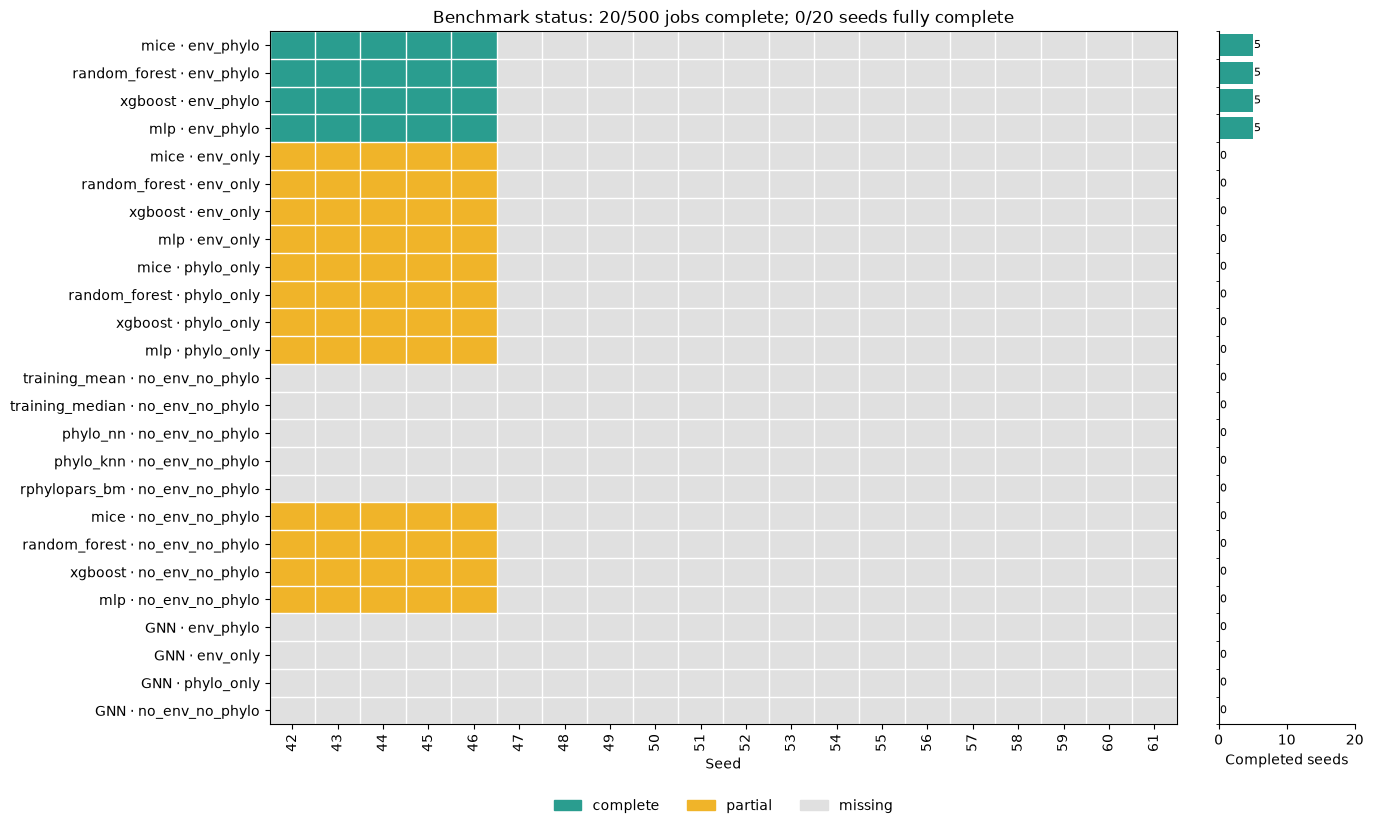

In [6]:
import json

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from run_benchmark import BASELINES, COVARIATE_BASELINES, find_baseline_results

manifest = json.loads((RESULTS_DIR / "manifest.json").read_text())
seeds = list(range(manifest["start_seed"], manifest["start_seed"] + manifest["n_seeds"]))
result_file = manifest["result_file"]
combinations = [(env, phylo, name) for env, phylo, name in manifest["feature_combinations"]]
STATUS = {"missing": 0, "partial": 1, "complete": 2}

jobs = []   # (label, check(seed) -> status)
for env, phylo, name in combinations:
    models = BASELINES if not (env or phylo) else COVARIATE_BASELINES
    for model in models:
        def check(seed, model=model, env=env, phylo=phylo):
            baseline_dir = RESULTS_DIR / "runs" / f"seed_{seed}" / "baselines"
            if baseline_dir.is_dir() and find_baseline_results(baseline_dir, (model,), result_file, env, phylo):
                return "complete"
            return "partial" if baseline_dir.is_dir() and any(baseline_dir.glob(f"{model.upper()}*")) else "missing"
        jobs.append((f"{model} · {name}", check))
for env, phylo, name in combinations:
    def check(seed, name=name):
        gnn_dir = RESULTS_DIR / "runs" / f"seed_{seed}" / "gnn" / name
        if any(gnn_dir.glob(f"*/{result_file}")):
            return "complete"
        return "partial" if gnn_dir.is_dir() and any(gnn_dir.iterdir()) else "missing"
    jobs.append((f"GNN · {name}", check))

status = np.array([[STATUS[check(seed)] for seed in seeds] for _, check in jobs])
n_done, n_total = int((status == 2).sum()), status.size
seed_done = (status == 2).all(axis=0)

fig, (ax, ax_bar) = plt.subplots(
    1, 2, figsize=(max(7, 0.45 * len(seeds) + 5), 0.28 * len(jobs) + 2),
    gridspec_kw={"width_ratios": [max(len(seeds), 4), 3], "wspace": 0.08}, sharey=True,
)
ax.imshow(status, aspect="auto", cmap=ListedColormap(["#e0e0e0", "#f0b429", "#2a9d8f"]), vmin=0, vmax=2)
ax.set_xticks(range(len(seeds)), [str(s) for s in seeds], rotation=90)
ax.set_yticks(range(len(jobs)), [label for label, _ in jobs])
ax.set_xticks(np.arange(-0.5, len(seeds)), minor=True)
ax.set_yticks(np.arange(-0.5, len(jobs)), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Seed")
ax.set_title(f"Benchmark status: {n_done}/{n_total} jobs complete; {int(seed_done.sum())}/{len(seeds)} seeds fully complete")

per_job = [(status[i] == 2).sum() for i in range(len(jobs))]
ax_bar.barh(range(len(jobs)), per_job, color="#2a9d8f")
ax_bar.set_xlim(0, len(seeds))
ax_bar.set_xlabel("Completed seeds")
ax_bar.tick_params(left=False)
for i, v in enumerate(per_job):
    ax_bar.text(v + 0.2, i, str(v), va="center", fontsize=8)
for spine in ("top", "right"):
    ax_bar.spines[spine].set_visible(False)
ax.legend(handles=[Patch(color=c, label=l) for l, c in (("complete", "#2a9d8f"), ("partial", "#f0b429"), ("missing", "#e0e0e0"))],
          loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False)
plt.show()

## 1. Load original-scale predictions and check consistency

In [5]:
predictions = load_benchmark_predictions(RESULTS_DIR)   # raises on any inconsistency
coverage = load_tree_coverage(RESULTS_DIR)

print(f"{len(predictions):,} prediction rows; seeds: {predictions.seed.nunique()}")
print(f"Cohort: {predictions.species.nunique()} taxa; absent from the tree: {int((~coverage.in_tree).sum())}")
display(coverage.loc[~coverage.in_tree, ["species", "placement"]])

FileNotFoundError: [Errno 2] No such file or directory: '/home/smonaco/newzeland-plants/benchmark_results/runs/seed_42/gnn'

## 2. Select the compared models and restrict to common species

Reference (trait/tree-only) baselines have no input variants. Covariate baselines are taken with environment + phylogeny inputs, matching the full GNN.

In [ ]:
COMPARISON_CONFIGURATION = "full"

is_reference = predictions.model.map(lambda m: not MODEL_SPECS[m].uses_covariates and m != "gnn")
selected = predictions.loc[is_reference | predictions.configuration_id.eq(COMPARISON_CONFIGURATION)]

cells = baseline_comparison_cells(selected, coverage=coverage)
print(f"Scored species: {cells.attrs['n_species']}; excluded for every model: {cells.attrs['excluded_species']}")
display(cells.groupby(["model_label"], observed=True).size().rename("scored cells (all seeds)").to_frame())

## 3. Global metrics per seed

Within each seed, RMSE, MAE, median absolute error and correlations are computed from the pooled evaluated cells of all folds. NRMSE-IQR divides RMSE by the IQR of the output over **all observed values of the analytical cohort** (fixed per output and identical for every model and subset).

In [ ]:
scales = cohort_scales(predictions)          # full cohort, not the filtered subset
seed_metrics = global_metrics(cells, scales)
summary = summarize_seeds(seed_metrics)
display(scales)

## 4. NRMSE-IQR comparison table

Mean across seeds; lower is better. **Bold**: best; *underlined*: second best. Rankings of point estimates are descriptive and do not establish statistical superiority.

In [ ]:
def highlight_top_two(column, kind="style"):
    ranks = pd.to_numeric(column, errors="coerce").rank(method="min", ascending=True, na_option="bottom")
    styles = {
        "style": ("background-color: lightgreen; font-weight: bold", "background-color: khaki; text-decoration: underline"),
        "latex": ("bfseries: ;", "itshape: ; underline: --rwrap;"),
    }[kind]
    return [styles[0] if r == 1 else styles[1] if r == 2 else "" for r in ranks]

nrmse_table = comparison_table(summary, "NRMSE_IQR")
display(label_output_columns(nrmse_table).style.apply(highlight_top_two, axis=0).format(precision=3, na_rep="--"))

## 5. Errors in original units, IQR denominators and sample sizes

In [ ]:
for metric in ("RMSE", "MAE", "MedAE"):
    print(f"{metric} (original units)")
    display(label_output_columns(comparison_table(summary, metric)).style.format(precision=2, na_rep="--"))

sample_table = summary.drop_duplicates(["trait", "variable"]).set_index(["trait", "variable"])[["n", "observed_n", "trait_iqr"]]
sample_table.columns = ["scored cells per seed (common species)", "observed cells (full cohort)", "IQR"]
display(sample_table)

## 6. Mean ± SD across seeds

The SD describes variability across repeated, overlapping splits and training randomness; it is not a prediction interval.

In [ ]:
std_table = comparison_table(summary, "NRMSE_IQR_std")
mean_sd_table = nrmse_table.copy().astype(object)
for row in mean_sd_table.index:
    for col in mean_sd_table.columns:
        mean_value, std_value = nrmse_table.loc[row, col], std_table.loc[row, col]
        mean_sd_table.loc[row, col] = "--" if pd.isna(mean_value) else (
            f"{mean_value:.3f}" if pd.isna(std_value) else f"{mean_value:.3f} ± {std_value:.3f}")
display(label_output_columns(mean_sd_table))
display(comparison_table(summary, "n_seeds").astype("Int64"))

## 7. LaTeX export

In [ ]:
latex = (
    label_output_columns(nrmse_table).style
    .apply(highlight_top_two, axis=0, kind="latex")
    .format(precision=3, na_rep="--")
    .format_index(escape="latex", axis=0)
    .format_index(escape="latex", axis=1)
    .to_latex(
        caption=(
            "Mean NRMSE-IQR across benchmark seeds for each trait and bound. Errors are computed on the "
            f"original scale from the pooled outer-fold predictions of the {cells.attrs['n_species']} taxa "
            "represented in the reconstructed phylogeny, so that every method is scored on the same cells; "
            "the IQR is that of all observed values in the analytical cohort. The best (lowest) value for "
            "each output is shown in bold and the second-best value is underlined."
        ),
        label="tab:performance_traits", hrules=True, multicol_align="c",
        column_format="l" + "c" * nrmse_table.shape[1],
    )
)
print(latex)

# Interpretation notes

1. Every model is scored on identical cells: the same species, folds, observed targets and evaluated outputs (checked).
2. Metrics are computed globally from original-scale predictions, pooled over folds within a seed, then summarized across seeds.
3. The NRMSE-IQR denominator is fixed per output (full analytical cohort).
4. Taxa absent from the tree are excluded from this comparison only; GNN training and GNN-only analyses (ablation, attribution) use all taxa.
5. Between-seed SDs are not prediction intervals; paired differences with an appropriate resampling scheme are still required before claiming superiority.